Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

print("Environment ready.")


Environment ready.


Load data

In [2]:
from google.colab import files

print("Upload hillstrom_email.csv")
uploaded = files.upload()

df = pd.read_csv('hillstrom_email.csv')
print(f"Rows    : {len(df):,}")
print(f"Columns : {df.shape[1]}")
print()
print(df.dtypes)


Upload hillstrom_email.csv


Saving hillstrom_email.csv to hillstrom_email (1).csv
Rows    : 64,000
Columns : 12

recency              int64
history_segment     object
history            float64
mens                 int64
womens               int64
zip_code            object
newbie               int64
channel             object
segment             object
visit                int64
conversion           int64
spend              float64
dtype: object


Data overview and quality check

In [3]:
print("=== SHAPE ===")
print(f"  {len(df):,} customers × {df.shape[1]} columns")

print("\n=== NULL VALUES ===")
nulls = df.isnull().sum()
print(nulls[nulls > 0] if nulls.sum() > 0 else "  No nulls — clean dataset.")

print("\n=== COLUMN DESCRIPTIONS ===")
desc = {
    'recency'         : 'Months since last purchase (pre-treatment)',
    'history_segment' : 'Prior-year spend tier — categorical (pre-treatment)',
    'history'         : 'Prior-year spend in £ (pre-treatment)',
    'mens'            : '1 = bought mens items before (pre-treatment)',
    'womens'          : '1 = bought womens items before (pre-treatment)',
    'zip_code'        : 'Urban / Suburban / Rural (pre-treatment)',
    'newbie'          : '1 = new customer in past 12 months (pre-treatment)',
    'channel'         : 'Acquisition channel: Phone / Web / Multichannel (pre-treatment)',
    'segment'         : 'TREATMENT: Mens E-Mail / Womens E-Mail / No E-Mail (control)',
    'visit'           : 'OUTCOME: visited website within 2 weeks (1/0)',
    'conversion'      : 'OUTCOME: made a purchase within 2 weeks (1/0)',
    'spend'           : 'OUTCOME: £ spent within 2 weeks',
}
for col, note in desc.items():
    print(f"  {col:<20} {note}")

print("\n=== TREATMENT GROUPS ===")
print(df['segment'].value_counts())

print("\n=== OUTCOME SUMMARY ===")
print(df[['visit', 'conversion', 'spend']].describe().round(4))

=== SHAPE ===
  64,000 customers × 12 columns

=== NULL VALUES ===
  No nulls — clean dataset.

=== COLUMN DESCRIPTIONS ===
  recency              Months since last purchase (pre-treatment)
  history_segment      Prior-year spend tier — categorical (pre-treatment)
  history              Prior-year spend in £ (pre-treatment)
  mens                 1 = bought mens items before (pre-treatment)
  womens               1 = bought womens items before (pre-treatment)
  zip_code             Urban / Suburban / Rural (pre-treatment)
  newbie               1 = new customer in past 12 months (pre-treatment)
  channel              Acquisition channel: Phone / Web / Multichannel (pre-treatment)
  segment              TREATMENT: Mens E-Mail / Womens E-Mail / No E-Mail (control)
  visit                OUTCOME: visited website within 2 weeks (1/0)
  conversion           OUTCOME: made a purchase within 2 weeks (1/0)
  spend                OUTCOME: £ spent within 2 weeks

=== TREATMENT GROUPS ===
segment


Randomisation balance check

This is the most important step before any analysis. If the randomisation failed, every lift number we calculate is meaningless. We check that pre-treatment features look the same across all three groups.

Pre-treatment feature means by group (should be nearly identical):
          Control  Mens Email  Womens Email  Max diff
recency    5.7497      5.7736        5.7678    0.0239
history  240.8827    242.8359      242.5366    1.9533
mens       0.5532      0.5509        0.5489    0.0043
womens     0.5476      0.5514        0.5501    0.0038
newbie     0.5020      0.5015        0.5032    0.0017

If 'Max diff' is close to 0 across all features, randomisation succeeded.


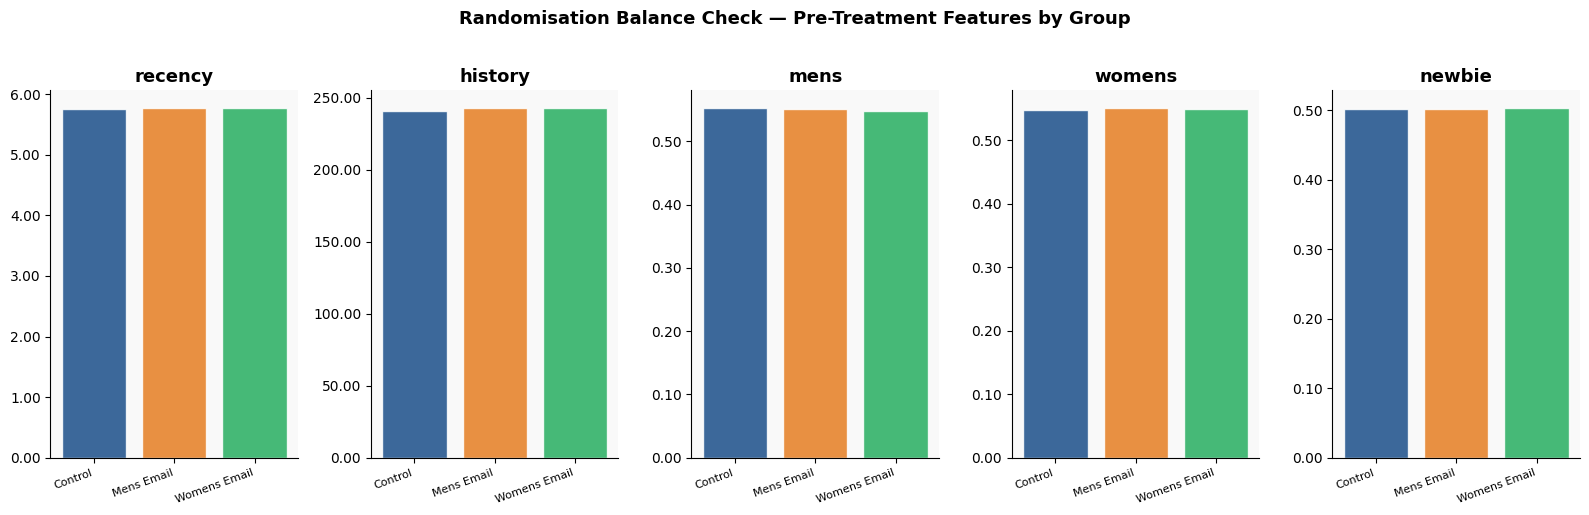


Why this matters in interviews:
A/B test results are only valid if treatment assignment was random.
Balance checking proves the groups were comparable BEFORE treatment.
If groups were imbalanced, any lift we observe could be due to
pre-existing differences, not the email campaign itself.


In [4]:
# Pre-treatment features to check
pre_features = ['recency', 'history', 'mens', 'womens', 'newbie']

groups = {
    'Control'      : df[df['segment'] == 'No E-Mail'],
    'Mens Email'   : df[df['segment'] == 'Mens E-Mail'],
    'Womens Email' : df[df['segment'] == 'Womens E-Mail'],
}

balance = {}
for feat in pre_features:
    row = {}
    for name, grp in groups.items():
        row[name] = grp[feat].mean()
    balance[feat] = row

balance_df = pd.DataFrame(balance).T
balance_df['Max diff'] = balance_df.max(axis=1) - balance_df.min(axis=1)
print("Pre-treatment feature means by group (should be nearly identical):")
print(balance_df.round(4).to_string())
print()
print("If 'Max diff' is close to 0 across all features, randomisation succeeded.")

# Visualise
fig, axes = plt.subplots(1, len(pre_features), figsize=(16, 5))
fig.suptitle('Randomisation Balance Check — Pre-Treatment Features by Group',
             fontsize=13, fontweight='bold', y=1.02)
colors = [BLUE, ORANGE, GREEN]
for i, feat in enumerate(pre_features):
    vals = [grp[feat].mean() for grp in groups.values()]
    axes[i].bar(groups.keys(), vals, color=colors, alpha=0.85, edgecolor='white')
    axes[i].set_title(feat, fontweight='bold')
    axes[i].set_xticklabels(groups.keys(), rotation=20, ha='right', fontsize=8)
    axes[i].yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

plt.tight_layout()
plt.savefig(FIGURES / '01_balance_check.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print("Why this matters in interviews:")
print("A/B test results are only valid if treatment assignment was random.")
print("Balance checking proves the groups were comparable BEFORE treatment.")
print("If groups were imbalanced, any lift we observe could be due to")
print("pre-existing differences, not the email campaign itself.")


 Statistical balance test (chi-square)

In [5]:
# Chi-square test for categorical features to formally test balance
cat_features = ['zip_code', 'channel', 'newbie']
print("Chi-square tests for balance across treatment groups:")
print("(p > 0.05 means groups are statistically balanced on this feature)\n")

for feat in cat_features:
    ct = pd.crosstab(df['segment'], df[feat])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    status = "BALANCED ✓" if p > 0.05 else "IMBALANCED ✗"
    print(f"  {feat:<15}  chi2={chi2:.2f}  p={p:.4f}  → {status}")

print()
# ANOVA for numerical features
num_features = ['recency', 'history']
print("One-way ANOVA for numerical features:")
print("(p > 0.05 means no significant difference across groups)\n")

for feat in num_features:
    groups_data = [grp[feat].values for grp in groups.values()]
    f_stat, p = stats.f_oneway(*groups_data)
    status = "BALANCED ✓" if p > 0.05 else "IMBALANCED ✗"
    print(f"  {feat:<15}  F={f_stat:.4f}  p={p:.4f}  → {status}")

print()
print("If all features pass: randomisation was successful.")
print("We can now trust that any lift we observe was caused by the email, not pre-existing differences.")


Chi-square tests for balance across treatment groups:
(p > 0.05 means groups are statistically balanced on this feature)

  zip_code         chi2=2.87  p=0.5795  → BALANCED ✓
  channel          chi2=3.63  p=0.4580  → BALANCED ✓
  newbie           chi2=0.14  p=0.9339  → BALANCED ✓

One-way ANOVA for numerical features:
(p > 0.05 means no significant difference across groups)

  recency          F=0.2704  p=0.7631  → BALANCED ✓
  history          F=0.3595  p=0.6980  → BALANCED ✓

If all features pass: randomisation was successful.
We can now trust that any lift we observe was caused by the email, not pre-existing differences.


Aggregate outcomes by group

In [7]:
agg = df.groupby('segment').agg(
    Customers=('visit', 'count'),
    Visit_Rate=('visit', 'mean'),
    Conversion_Rate=('conversion', 'mean'),
    Avg_Spend=('spend', 'mean'),
    Total_Spend=('spend', 'sum'),
).reset_index()

control_visit  = agg.loc[agg['segment'] == 'No E-Mail', 'Visit_Rate'].values[0]
control_conv   = agg.loc[agg['segment'] == 'No E-Mail', 'Conversion_Rate'].values[0]
control_spend  = agg.loc[agg['segment'] == 'No E-Mail', 'Avg_Spend'].values[0]

agg['Visit Lift (pp)']      = (agg['Visit_Rate']      - control_visit)  * 100
agg['Conversion Lift (pp)'] = (agg['Conversion_Rate'] - control_conv)   * 100
agg['Spend Lift (£)']       = agg['Avg_Spend']        - control_spend

print("Aggregate outcomes by treatment group:")
print(agg.to_string(index=False))
print()


Aggregate outcomes by treatment group:
      segment  Customers  Visit_Rate  Conversion_Rate  Avg_Spend  Total_Spend  Visit Lift (pp)  Conversion Lift (pp)  Spend Lift (£)
  Mens E-Mail      21307    0.182757         0.012531   1.422617     30311.69         7.658956              0.680501        0.769827
    No E-Mail      21306    0.106167         0.005726   0.652789     13908.33         0.000000              0.000000        0.000000
Womens E-Mail      21387    0.151400         0.008837   1.077202     23038.11         4.523311              0.311106        0.424412



Lift visualisation

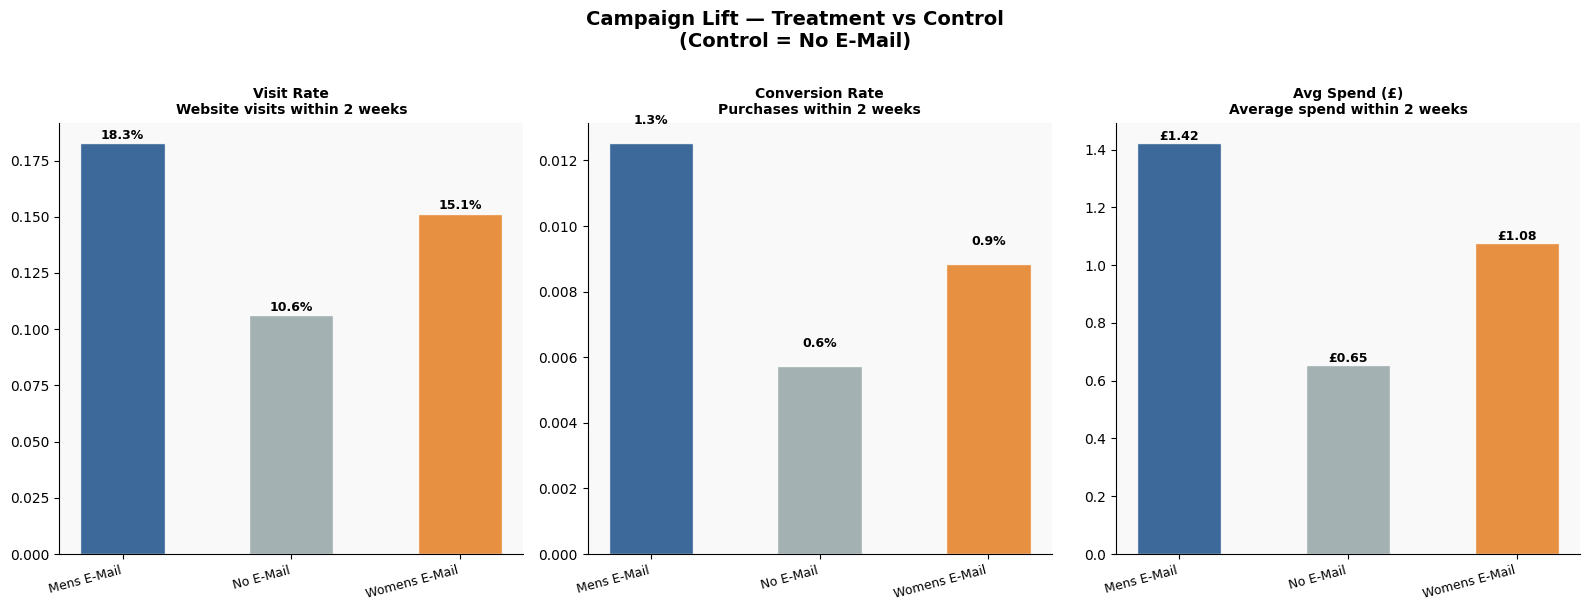

Mens email   — incremental spend lift : £0.77/customer → £16,403 total
Womens email — incremental spend lift : £0.42/customer → £9,077 total



In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Campaign Lift — Treatment vs Control\n(Control = No E-Mail)',
             fontsize=14, fontweight='bold', y=1.01)

metrics = [
    ('Visit_Rate',      'Visit Rate',      '.1%', 'Website visits within 2 weeks'),
    ('Conversion_Rate', 'Conversion Rate', '.1%', 'Purchases within 2 weeks'),
    ('Avg_Spend',       'Avg Spend (£)',   '£.2f', 'Average spend within 2 weeks'),
]
seg_colors = {'No E-Mail': GREY, 'Mens E-Mail': BLUE, 'Womens E-Mail': ORANGE}

for ax, (col, label, fmt, subtitle) in zip(axes, metrics):
    bars = ax.bar(agg['segment'], agg[col],
                  color=[seg_colors[s] for s in agg['segment']],
                  alpha=0.85, edgecolor='white', width=0.5)
    ax.set_title(f"{label}\n{subtitle}", fontweight='bold', fontsize=10)
    ax.set_xticklabels(agg['segment'], rotation=15, ha='right', fontsize=9)
    for bar, val in zip(bars, agg[col]):
        if fmt == '£.2f':
            label_txt = f'£{val:.2f}'
        else:
            label_txt = f'{val*100:.1f}%'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
                label_txt, ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES / '02_aggregate_lift.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary
mens_spend_lift   = agg.loc[agg['segment'] == 'Mens E-Mail',   'Spend Lift (£)'].values[0]
womens_spend_lift = agg.loc[agg['segment'] == 'Womens E-Mail', 'Spend Lift (£)'].values[0]
mens_n            = agg.loc[agg['segment'] == 'Mens E-Mail',   'Customers'].values[0]
womens_n          = agg.loc[agg['segment'] == 'Womens E-Mail', 'Customers'].values[0]

print(f"Mens email   — incremental spend lift : £{mens_spend_lift:.2f}/customer → £{mens_spend_lift*mens_n:,.0f} total")
print(f"Womens email — incremental spend lift : £{womens_spend_lift:.2f}/customer → £{womens_spend_lift*womens_n:,.0f} total")
print()


Spend distribution

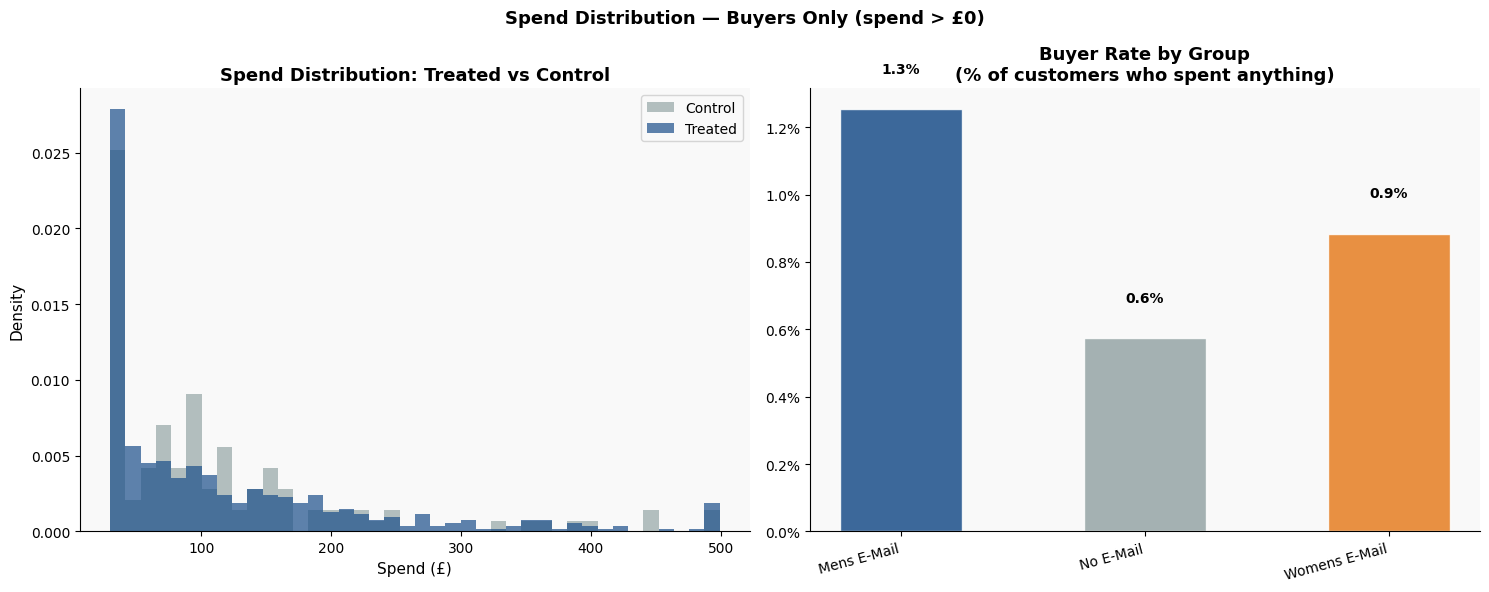

In [9]:
treated = df[df['segment'] != 'No E-Mail']
control = df[df['segment'] == 'No E-Mail']

# Only buyers — spend=0 dominates the chart otherwise
buyers_treated = treated[treated['spend'] > 0]
buyers_control = control[control['spend'] > 0]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Spend Distribution — Buyers Only (spend > £0)',
             fontsize=13, fontweight='bold')

axes[0].hist(buyers_control['spend'],  bins=40, color=GREY,  alpha=0.7, label='Control',  density=True)
axes[0].hist(buyers_treated['spend'],  bins=40, color=BLUE,  alpha=0.7, label='Treated',  density=True)
axes[0].set_title('Spend Distribution: Treated vs Control', fontweight='bold')
axes[0].set_xlabel('Spend (£)')
axes[0].set_ylabel('Density')
axes[0].legend()

non_zero = df.groupby('segment')['spend'].apply(lambda x: (x > 0).mean()).reset_index()
non_zero.columns = ['segment', 'Buyer Rate']
axes[1].bar(non_zero['segment'], non_zero['Buyer Rate'],
            color=[seg_colors[s] for s in non_zero['segment']],
            alpha=0.85, edgecolor='white', width=0.5)
axes[1].set_title('Buyer Rate by Group\n(% of customers who spent anything)', fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v*100:.1f}%'))
axes[1].set_xticklabels(non_zero['segment'], rotation=15, ha='right')
for i, row in non_zero.iterrows():
    axes[1].text(i, row['Buyer Rate'] + 0.001, f"{row['Buyer Rate']*100:.1f}%",
                 ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES / '03_spend_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


Where is the lift strongest? (segment breakdown)

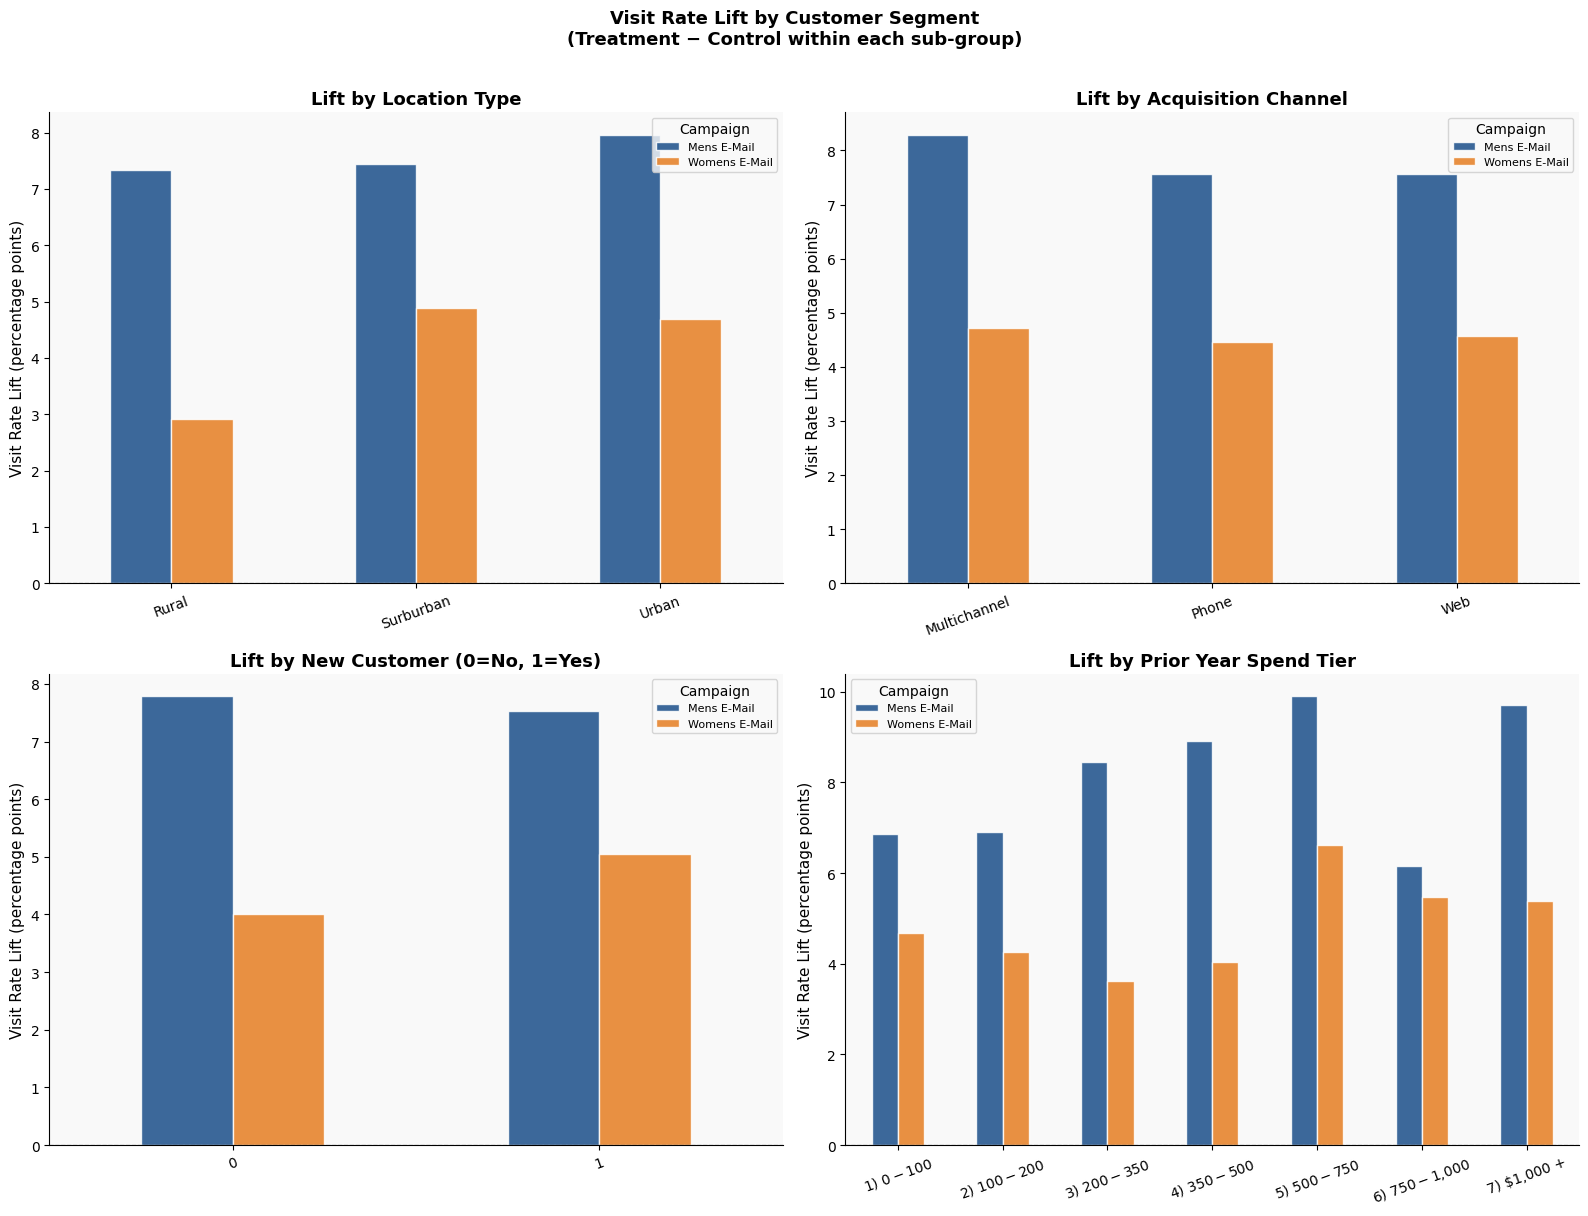

In [10]:
segment_vars = ['zip_code', 'channel', 'newbie', 'history_segment']
segment_labels = {
    'zip_code'        : 'Location Type',
    'channel'         : 'Acquisition Channel',
    'newbie'          : 'New Customer (0=No, 1=Yes)',
    'history_segment' : 'Prior Year Spend Tier',
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Visit Rate Lift by Customer Segment\n(Treatment − Control within each sub-group)',
             fontsize=13, fontweight='bold', y=1.01)

for ax, var in zip(axes.flatten(), segment_vars):
    grp = df.groupby([var, 'segment'])['visit'].mean().reset_index()
    ctrl = grp[grp['segment'] == 'No E-Mail'].rename(columns={'visit': 'control_rate'})
    lift = grp[grp['segment'] != 'No E-Mail'].merge(ctrl[[var, 'control_rate']], on=var)
    lift['Lift (pp)'] = (lift['visit'] - lift['control_rate']) * 100

    pivot = lift.pivot(index=var, columns='segment', values='Lift (pp)')
    pivot.plot(kind='bar', ax=ax, color=[BLUE, ORANGE], alpha=0.85, edgecolor='white')
    ax.set_title(f'Lift by {segment_labels[var]}', fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Visit Rate Lift (percentage points)')
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.tick_params(axis='x', rotation=20)
    ax.legend(title='Campaign', fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES / '04_lift_by_segment.png', dpi=150, bbox_inches='tight')
plt.show()



Save processed data

In [11]:
# Create binary treatment columns for modeling in later notebooks
df['treatment_mens']   = (df['segment'] == 'Mens E-Mail').astype(int)
df['treatment_womens'] = (df['segment'] == 'Womens E-Mail').astype(int)
df['treatment_any']    = (df['segment'] != 'No E-Mail').astype(int)

# Encode categoricals
df['zip_code_enc'] = df['zip_code'].map({'Urban': 0, 'Suburban': 1, 'Rural': 2})
df['channel_enc']  = df['channel'].map({'Phone': 0, 'Web': 1, 'Multichannel': 2})

out_path = PROCESSED / 'hillstrom_clean.csv'
df.to_csv(out_path, index=False)
print(f"Saved: {out_path}  ({len(df):,} rows, {df.shape[1]} columns)")
print()
print("New columns added:")
print("  treatment_any   : 1 = received any email (for binary uplift models)")
print("  treatment_mens  : 1 = received mens email")
print("  treatment_womens: 1 = received womens email")
print("  zip_code_enc    : ordinal-encoded zip_code")
print("  channel_enc     : ordinal-encoded channel")
print()
print("Download hillstrom_clean.csv from /content/processed/ before closing Colab.")


Saved: /content/processed/hillstrom_clean.csv  (64,000 rows, 17 columns)

New columns added:
  treatment_any   : 1 = received any email (for binary uplift models)
  treatment_mens  : 1 = received mens email
  treatment_womens: 1 = received womens email
  zip_code_enc    : ordinal-encoded zip_code
  channel_enc     : ordinal-encoded channel

Download hillstrom_clean.csv from /content/processed/ before closing Colab.
